# Model Experiments and Pipeline Walkthrough

## Goal
Inspect the selected M3 stack, replay the recorded comparison, and pass one image pair through the reusable pipeline. The default CPU execution uses an **Otsu/template integration control** and a defer-only decision control. Choose `RUN_LEARNED=True` to use BIT, RSCaMa and Qwen after supplying checkpoints and worker interpreters. Historical model measurements and fresh control outputs have separate labels.

The main implementations live in `src/`. The POC originals remain available for reproducing their original protocols.

## 1. Setup and run parameters

In [1]:
from pathlib import Path
import os, sys, json, subprocess, importlib.util
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/pipeline.json').exists()), None)
if PROJECT_ROOT is None and IN_COLAB:
    PROJECT_ROOT = Path('/content/TerraWatch')
    subprocess.run(['git','clone','--branch','model-pipeline','https://github.com/shoaib2000857/Group-7-DS-and-AI-Lab-Project.git',str(PROJECT_ROOT)],check=True)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from a clone of the model-pipeline branch.')
os.chdir(PROJECT_ROOT)
sys.path.insert(0,str(PROJECT_ROOT))
if IN_COLAB:
    subprocess.run([sys.executable,'-m','pip','install','-q','-r','requirements-pipeline.txt'],check=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from datetime import datetime, timezone
plt.rcParams.update({'figure.figsize':(10,3.4),'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
RUN = PROJECT_ROOT/'outputs/model_notebooks'/datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
RUN.mkdir(parents=True,exist_ok=False)
PROCESSED = Path(os.environ.get('TERRAWATCH_PROCESSED',str(PROJECT_ROOT/'data/processed')))
CONFIG_PATH = PROJECT_ROOT/'configs/pipeline.json'
CONFIG = json.loads(CONFIG_PATH.read_text())
print('Run:',RUN)


Run: D:\IITM\DegreeTerm3\DSAI\Project\outputs\model_notebooks\20261110_163651_375026


## 2. Recorded model comparison
Source: `docs/milestone3/evidence/caption_benchmark_proof.json`, supplied local run dated 9 November 2026. Percentages use automatic mask/reference checks on the frozen 100-pair screen.

,Model,Strict precision (%),In-scope precision (%),BLEU-4
0,RSCaMa (specialist),78.69,88.89,0.6223
1,RSCaMa retrained on 20% (ours),76.04,82.02,0.5793
2,SmolVLM2-2.2B,37.76,47.13,0.0000
3,Qwen3-VL-4B,55.70,71.74,0.0183
4,Evidence template (pixel difference),69.00,69.00,0.0000
5,"Constant ""there is no difference""",40.00,40.00,0.2798


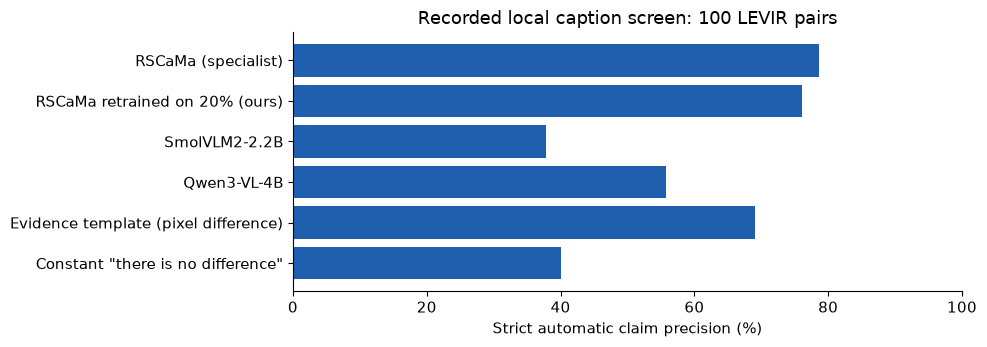

In [2]:
proof = json.loads(Path('docs/milestone3/evidence/caption_benchmark_proof.json').read_text())
comparison = pd.DataFrame([{'Model':r['configuration'], 'Strict precision (%)':100*r['metrics']['strict_precision']['local_rerun'], 'In-scope precision (%)':100*r['metrics']['in_scope_precision']['local_rerun'], 'BLEU-4':r['metrics']['BLEU-4']['local_rerun']} for r in proof['comparisons']])
display(comparison.round(4))
fig, ax = plt.subplots(figsize=(10,3.6))
ax.barh(comparison['Model'],comparison['Strict precision (%)'],color='#1f5fae')
ax.invert_yaxis();ax.set_xlim(0,100);ax.set_xlabel('Strict automatic claim precision (%)');ax.set_title('Recorded local caption screen: 100 LEVIR pairs')
fig.tight_layout();plt.show()


## 3. Inspect configured model assets
The preflight checks paths and the acceptance threshold without downloading weights. Set the three interpreter paths in `configs/pipeline.json` to the separately installed model environments.

In [3]:
from src.inference.preflight import inspect_config
setup = inspect_config(CONFIG)
display(pd.DataFrame(setup['checks']))


,stage,item,value,ready
0,detector,python,python,True
1,detector,source_dir,models/external/BIT_CD,False
2,detector,checkpoint,models/checkpoints/bit_mci.pt,False
3,captioner,python,python,True
4,captioner,source_dir,models/external/RSCaMa,False
5,captioner,checkpoint,models/checkpoints/rscama.pth,False
6,captioner,vocab,models/checkpoints/rscama_vocab.json,False
7,referee,python,python,True
8,referee,revision,ebb281ec70b05090aa6165b016eac8ec08e71b17,True
9,referee,accept_threshold,0.8,True


## 4. Select a temporal image pair
Use the first prepared validation MCI pair when the data handover is present. A clearly labelled synthetic routing fixture provides a portable CPU walkthrough in a fresh clone. Training and benchmark results are never calculated from that fixture.

Input source: prepared validation MCI pair ; pair: levir_mci/val/val_000001


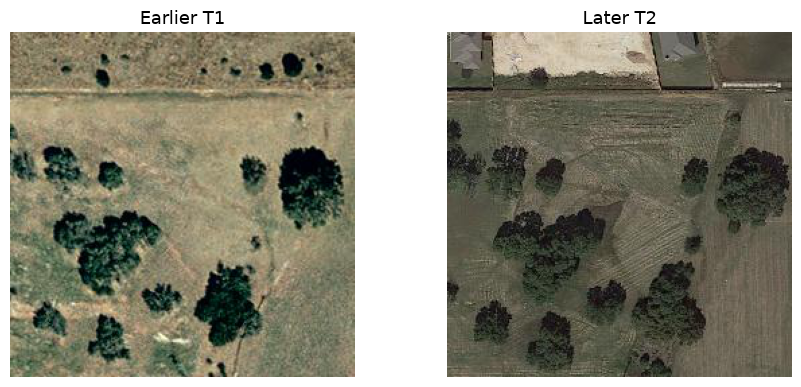

In [4]:
from PIL import Image
from src.inference.controls import make_fixture
from src.data.dataset import PairDataset
manifest = PROCESSED/'val.jsonl'
if manifest.exists():
    dataset=PairDataset(manifest,PROCESSED,include_targets=False)
    try:
        dataset.rows=[r for r in dataset.rows if r['dataset']=='levir_mci']
        sample=dataset[0];pair_id=sample['pair_id'];paths=[]
        for key in ['t1','t2']:
            path=RUN/(key+'.png');Image.fromarray(sample[key]).save(path);paths.append(path)
        input_source='prepared validation MCI pair'
    finally:dataset.close()
else:
    paths=make_fixture(RUN/'synthetic_input');pair_id='synthetic_routing_fixture';input_source='synthetic routing fixture'
print('Input source:',input_source,'; pair:',pair_id)
fig, axes=plt.subplots(1,2,figsize=(9,4))
for ax,path,title in zip(axes,paths,['Earlier T1','Later T2']):ax.imshow(Image.open(path));ax.set_title(title);ax.axis('off')
fig.tight_layout();plt.show()


## 5. Execute the pipeline
The CPU control exercises parsing, localisation, crop inspection, decision routing and report composition. Its mask assumes that changed pixels represent the building class solely for integration testing. The learned mode uses the independent configured model workers.

In [5]:
RUN_LEARNED = False
from src.inference.pipeline import run_pipeline
from src.inference.controls import control_worker
pipeline_run=RUN/'pipeline'
if RUN_LEARNED:
    if input_source=='synthetic routing fixture':raise ValueError('Select real images for learned model evaluation')
    checked=inspect_config(CONFIG,environments=True)
    if not checked['ready']:raise RuntimeError('Resolve the preflight checks before launching the learned stack')
    result=run_pipeline(*paths,CONFIG,pipeline_run,pair_id=pair_id)
else:
    result=run_pipeline(*paths,CONFIG,pipeline_run,pair_id=pair_id,worker=control_worker(pipeline_run))
print('Execution mode:',result['execution_mode'])
print('Description:',result['verified_description'])
print('Errors:',result['errors'])
claims=pd.DataFrame([{'Claim':c['source_span'],'Decision':c['decision']['outcome'],'Reasons':', '.join(c['decision']['reason_codes'])} for c in result['claims']])
display(claims)


Execution mode: deterministic_integration_control
Description: The image pair requires review before a change description can be confirmed.
Errors: []


""


## 6. Inspect intermediate evidence

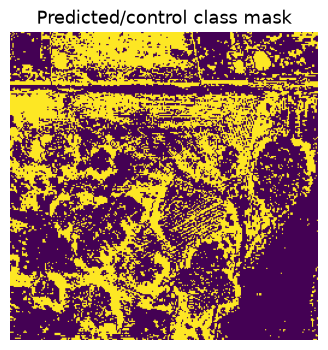

In [6]:
mask_path=pipeline_run/('detector_response.mask.png' if RUN_LEARNED else 'control_mask.png')
if mask_path.exists():
    fig,ax=plt.subplots(figsize=(5,4));ax.imshow(Image.open(mask_path),vmin=0,vmax=2,cmap='viridis');ax.set_title('Predicted/control class mask');ax.axis('off');plt.show()
if result['claims']:
    evidence=result['claims'][0]['evidence'];display(pd.DataFrame([{'Visible change':evidence['visible_change'],'Observation':evidence['observations'],'Frame':result['claims'][0]['coordinate_frame']}]))
    fig,axes=plt.subplots(1,2,figsize=(8,3))
    for ax,path in zip(axes,evidence['crop_paths']):ax.imshow(Image.open(path));ax.axis('off')
    fig.suptitle('Matched T1/T2 crop evidence');plt.show()


## 7. Training entry points
These commands call the same modules as the CLI. The JSON profiles define the full task-training configuration. The recorded two-epoch experiment keeps its separate raw-archive protocol in the preserved POC source.

In [7]:
RUN_TRAINING = False
training_commands = [
    [sys.executable,'scripts/train_models.py','detector','--config','configs/detector_training.json','--print-command'],
    [sys.executable,'scripts/train_models.py','captioner','--config','configs/captioner_training.json','--print-command']]
for command in training_commands:
    subprocess.run(command,check=True)
if RUN_TRAINING:
    # Use each task's own interpreter from CONFIG; remove --print-command to execute.
    for command,stage in zip(training_commands,['detector','captioner']):
        launch=command[:-1]+['--python',CONFIG[stage]['python']]
        subprocess.run(launch,check=True)


## 8. Downloadable handover
The ZIP includes this run's images, crops, responses and report with per-file hashes. Model weights and source datasets remain separate assets.

In [8]:
from scripts.package_model_run import package_run
archive=package_run(RUN,RUN.parent/(RUN.name+'_results.zip'))
print(archive)
if IN_COLAB:
    from google.colab import files
    files.download(str(archive))


D:\IITM\DegreeTerm3\DSAI\Project\outputs\model_notebooks\20261110_163651_375026_results.zip
